# 05 · 품질 분류 예측과 OOS 조기경보
### 실습으로 배우는 GMP AI — 강의 목차 ⑥ 품질 분류 예측과 성능 평가

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StillWork/GMPAI/blob/main/05_Quality_Classification_OOS_Alert.ipynb)

| 항목 | 내용 |
|---|---|
| **학습 목표** | ① 불균형 데이터 분류 ② **비용 기반 임계값** 결정 ③ **확률 보정(calibration)** — 예측 확률을 믿을 수 있는가 ④ **SHAP** 으로 근거 설명 ⑤ 조기경보 운영 설계(경보 피로·Human-in-the-loop) |
| **데이터** | 실제 정제 생산 1,005 배치 |
| **실행 환경** | CPU · 약 10분 |

> 품질 분류 모델의 가치는 **정확도**가 아니라 **"조치할 수 있는 경보를 적시에 주는가"** 로 평가됩니다.

In [1]:
%pip install -q koreanize-matplotlib shap
import koreanize_matplotlib, os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
REPO = "https://raw.githubusercontent.com/StillWork/GMPAI/main/data/"
def load_data(name, **kw):
    local = os.path.join("data", name)
    return pd.read_csv(local if os.path.exists(local) else REPO + name, **kw)
df = load_data("tablet_batches.csv", parse_dates=["start_date"]).sort_values("start_date").reset_index(drop=True)

CQA = ["dissolution_av", "dissolution_min", "impurities_total", "impurity_o", "impurity_l", "residual_solvent"]
ID = ["batch", "code", "strength", "size", "start", "start_date",
      "api_code", "api_batch", "smcc_batch", "lactose_batch", "starch_batch"]
X = df[[c for c in df.columns if c not in CQA + ID]].select_dtypes("number")
X = X.fillna(X.median())
y = (df["impurities_total"] > 0.2).astype(int).values          # 위험 배치 = 불순물 0.2% 초과
n = len(df); cut = int(n * 0.8); tr, te = np.arange(cut), np.arange(cut, n)
print(f"학습 {len(tr)}배치 / 평가 {len(te)}배치 (시간 순)")
print(f"위험 배치 비율 — 학습 {y[tr].mean():.1%}, 평가 {y[te].mean():.1%}")

Note: you may need to restart the kernel to use updated packages.


학습 804배치 / 평가 201배치 (시간 순)
위험 배치 비율 — 학습 34.1%, 평가 24.4%


## 1. 불균형 데이터에서 분류 모델 만들기
불균형 대응 3가지 방법을 비교합니다.
| 방법 | 원리 | 주의 |
|---|---|---|
| `class_weight="balanced"` | 소수 클래스 오류에 더 큰 벌점 | 가장 간단, 1순위로 시도 |
| 오버샘플링(SMOTE 등) | 소수 클래스를 합성해 늘림 | **반드시 학습 데이터에만** 적용 |
| 임계값 조정 | 모델은 그대로, 판정 기준만 낮춤 | ✅ 가장 실용적·투명 |

In [2]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay, brier_score_loss)

models = {
    "로지스틱(가중치)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced")),
    "랜덤포레스트": RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=0),
    "랜덤포레스트(가중치)": RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=0, class_weight="balanced_subsample"),
    "그래디언트부스팅": GradientBoostingClassifier(random_state=0),
}
probs, rows = {}, []
for name, m in models.items():
    m.fit(X.iloc[tr], y[tr]); p = m.predict_proba(X.iloc[te])[:, 1]; probs[name] = p
    pred = (p >= 0.5).astype(int)
    rows.append({"모델": name, "정밀도": precision_score(y[te], pred, zero_division=0), "재현율": recall_score(y[te], pred),
                 "F1": f1_score(y[te], pred), "ROC-AUC": roc_auc_score(y[te], p),
                 "PR-AUC": average_precision_score(y[te], p), "Brier": brier_score_loss(y[te], p)})
res = pd.DataFrame(rows).round(3)
display(res)
print(f"무작위 기준선 PR-AUC = {y[te].mean():.3f}   (Brier 점수는 낮을수록 확률이 정확)")

,모델,정밀도,재현율,F1,ROC-AUC,PR-AUC,Brier
0,로지스틱(가중치),0.373,0.776,0.503,0.828,0.708,0.252
1,랜덤포레스트,0.864,0.776,0.817,0.953,0.861,0.111
2,랜덤포레스트(가중치),0.846,0.673,0.750,0.946,0.825,0.115
3,그래디언트부스팅,0.712,0.857,0.778,0.927,0.866,0.095


무작위 기준선 PR-AUC = 0.244   (Brier 점수는 낮을수록 확률이 정확)


## 2. ⭐ 비용 기반 임계값 — "몇 %에서 경보를 울릴 것인가"
0.5 는 기본값일 뿐 GMP 에 맞는 기준이 아닙니다. **FN(불량 놓침)과 FP(불필요 조사)의 비용**으로 정합니다.

| 구분 | 상황 | 비용 요소 |
|---|---|---|
| **FN** (놓침) | 불량 배치를 적합으로 판정 | 회수·재작업·일탈 조사·규제 리스크·환자 안전 |
| **FP** (오경보) | 정상 배치를 위험으로 판정 | 추가 시험·보류·생산 지연·**경보 피로** |

> 임계값은 **반드시 학습/검증 데이터로** 정해야 합니다. 평가 데이터로 정하면 성능이 부풀려집니다.

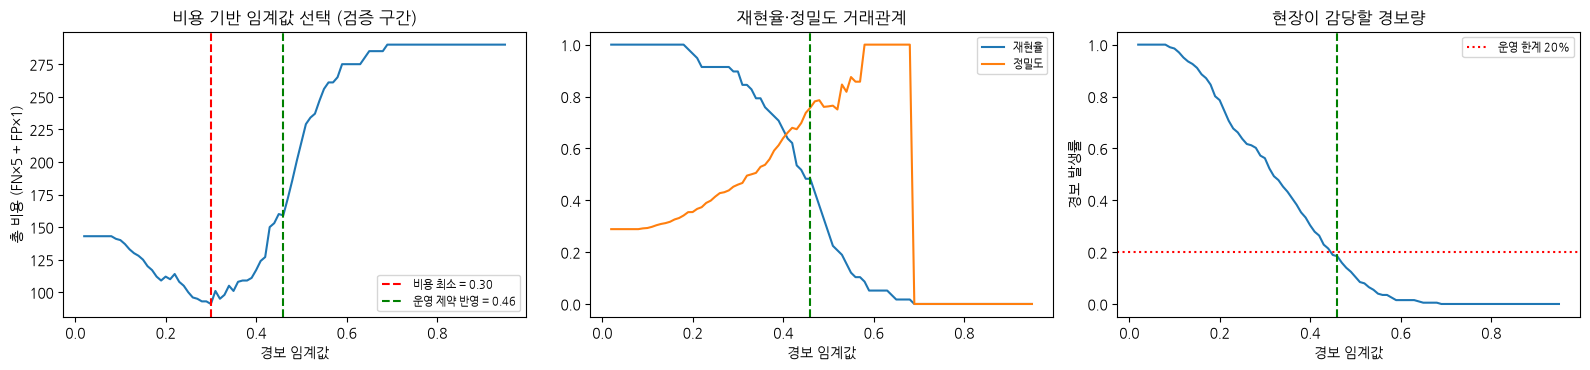

비용만 최소화한 임계값 = 0.30 (경보율 56%) ← 현장 적용 불가 수준
운영 제약(경보율 ≤ 20%)을 반영한 임계값 = 0.46


In [3]:
# 학습 구간을 다시 나눠 '검증 구간'을 만든다 (임계값 결정용)
cut2 = int(len(tr) * 0.75)
tr2, va = tr[:cut2], tr[cut2:]
clf = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=0, class_weight="balanced_subsample")
clf.fit(X.iloc[tr2], y[tr2])
p_va = clf.predict_proba(X.iloc[va])[:, 1]

C_FN, C_FP = 5, 1           # 불량 1건 놓침 = 오경보 5건 (회사 정책에 따라 조정)
MAX_ALERT_RATE = 0.20       # 현장이 감당 가능한 최대 경보 발생률 (운영 제약)

ths = np.linspace(0.02, 0.95, 94)
costs, recalls, precs, rates = [], [], [], []
for t in ths:
    pred = (p_va >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y[va], pred, labels=[0, 1]).ravel()
    costs.append(C_FN * fn + C_FP * fp)
    recalls.append(tp / max(1, tp + fn)); precs.append(tp / max(1, tp + fp)); rates.append(pred.mean())
costs, recalls, rates = np.array(costs), np.array(recalls), np.array(rates)

th_cost = ths[int(np.argmin(costs))]                                   # 비용만 최소화
ok = rates <= MAX_ALERT_RATE                                           # 운영 제약을 만족하는 임계값
th_oper = ths[int(np.argmin(np.where(ok, costs, np.inf)))] if ok.any() else th_cost

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].plot(ths, costs); ax[0].axvline(th_cost, color="red", ls="--", label=f"비용 최소 = {th_cost:.2f}")
ax[0].axvline(th_oper, color="green", ls="--", label=f"운영 제약 반영 = {th_oper:.2f}")
ax[0].set_xlabel("경보 임계값"); ax[0].set_ylabel(f"총 비용 (FN×{C_FN} + FP×{C_FP})"); ax[0].legend(fontsize=8); ax[0].set_title("비용 기반 임계값 선택 (검증 구간)")
ax[1].plot(ths, recalls, label="재현율"); ax[1].plot(ths, precs, label="정밀도")
ax[1].axvline(th_oper, color="green", ls="--"); ax[1].set_xlabel("경보 임계값"); ax[1].legend(fontsize=8); ax[1].set_title("재현율·정밀도 거래관계")
ax[2].plot(ths, rates); ax[2].axhline(MAX_ALERT_RATE, color="red", ls=":", label=f"운영 한계 {MAX_ALERT_RATE:.0%}")
ax[2].axvline(th_oper, color="green", ls="--"); ax[2].set_xlabel("경보 임계값"); ax[2].set_ylabel("경보 발생률"); ax[2].legend(fontsize=8); ax[2].set_title("현장이 감당할 경보량")
plt.tight_layout(); plt.show()
print(f"비용만 최소화한 임계값 = {th_cost:.2f} (경보율 {rates[int(np.argmin(costs))]:.0%}) ← 현장 적용 불가 수준")
print(f"운영 제약(경보율 ≤ {MAX_ALERT_RATE:.0%})을 반영한 임계값 = {th_oper:.2f}")

In [4]:
# 결정한 임계값을 '한 번도 안 쓴' 평가 구간에 적용
clf_full = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=0, class_weight="balanced_subsample").fit(X.iloc[tr], y[tr])
p_te = clf_full.predict_proba(X.iloc[te])[:, 1]
rows = []
for name, t in [("기본값 0.5", 0.5), (f"비용 최소 {th_cost:.2f}", th_cost), (f"운영 제약 반영 {th_oper:.2f}", th_oper)]:
    pred = (p_te >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y[te], pred, labels=[0, 1]).ravel()
    rows.append({"임계값": name, "잡아낸 위험(TP)": tp, "놓침(FN)": fn, "오경보(FP)": fp,
                 "재현율": tp / max(1, tp + fn), "정밀도": tp / max(1, tp + fp),
                 "총비용": C_FN * fn + C_FP * fp, "경보 발생률": pred.mean()})
pd.DataFrame(rows).round(3)

,임계값,잡아낸 위험(TP),놓침(FN),오경보(FP),재현율,정밀도,총비용,경보 발생률
0,기본값 0.5,33,16,6,0.673,0.846,86,0.194
1,비용 최소 0.30,49,0,52,1.000,0.485,52,0.502
2,운영 제약 반영 0.46,37,12,13,0.755,0.740,73,0.249


> **왜 비용만 최소화하면 안 되는가**: FN 비용이 FP 보다 훨씬 크면, 수학적 최적해는 "거의 모든 배치에 경보"가 됩니다.
> 재현율은 100%가 되지만 **경보의 정보 가치가 사라집니다**. 그래서 실무에서는 **운영 제약(경보율 상한)을 함께** 걸고 임계값을 정합니다.
>
> **운영 관점**: "경보 발생률"은 현장이 감당할 수 있는 수준이어야 합니다.
> 경보가 전체 배치의 30%에 뜨면 아무도 보지 않게 됩니다(**경보 피로**). 보통 **5~15%** 수준에서 운영하며,
> 경보 등급을 나누기도 합니다 (예: 확률 0.3~0.6 = 주의 관찰, 0.6 이상 = 즉시 조사).

## 3. ⭐ 확률 보정(Calibration) — "70% 위험"은 정말 70%인가
GMP 문서에 "이 배치의 불량 확률 70%"라고 쓰려면, **그 확률이 실제 빈도와 맞아야** 합니다.
- **보정 곡선**: 예측 확률 구간별 실제 발생률을 그려 대각선에 가까운지 확인
- **Brier 점수**: 확률 예측의 평균제곱오차 (낮을수록 좋음)
- 트리 앙상블은 확률이 **중앙으로 쏠리는** 경향이 있어 보정이 필요한 경우가 많습니다

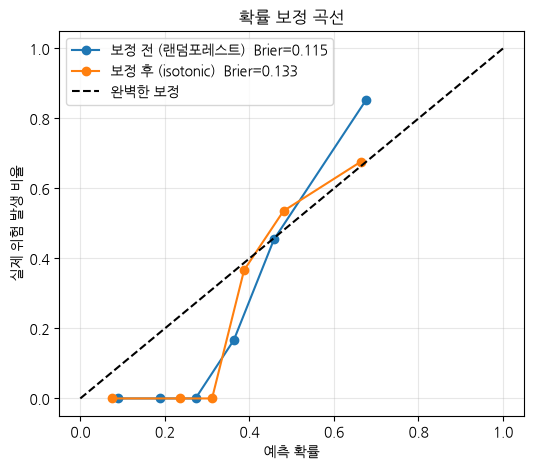

→ 점들이 대각선에 가까울수록 '예측 확률 = 실제 빈도'. 규제 문서에 확률을 쓰려면 보정은 필수입니다.


In [5]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
cal = CalibratedClassifierCV(RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=0,
                                                   class_weight="balanced_subsample"), method="isotonic", cv=3)
cal.fit(X.iloc[tr], y[tr])
p_cal = cal.predict_proba(X.iloc[te])[:, 1]

plt.figure(figsize=(6, 5))
for name, pp in [("보정 전 (랜덤포레스트)", p_te), ("보정 후 (isotonic)", p_cal)]:
    frac, mean_p = calibration_curve(y[te], pp, n_bins=6, strategy="quantile")
    plt.plot(mean_p, frac, "o-", label=f"{name}  Brier={brier_score_loss(y[te], pp):.3f}")
plt.plot([0, 1], [0, 1], "k--", label="완벽한 보정")
plt.xlabel("예측 확률"); plt.ylabel("실제 위험 발생 비율"); plt.legend(); plt.title("확률 보정 곡선"); plt.grid(alpha=0.3); plt.show()
print("→ 점들이 대각선에 가까울수록 '예측 확률 = 실제 빈도'. 규제 문서에 확률을 쓰려면 보정은 필수입니다.")

## 4. ⭐ SHAP — 경보의 근거를 설명하기
AI 경보가 떴을 때 현장이 묻는 첫 질문은 **"왜?"** 입니다.
**SHAP** 은 각 변수가 그 배치의 예측을 얼마나 밀어올렸는지 수치로 보여줍니다 — 규제기관 설명(설명가능성 요건)에도 사용됩니다.

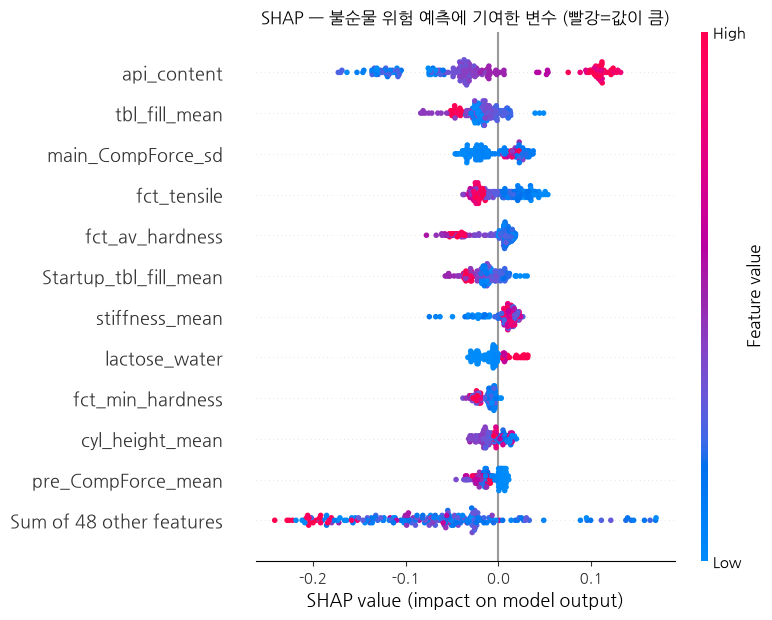

In [6]:
import shap
expl = shap.TreeExplainer(clf_full)
sv = expl(X.iloc[te], check_additivity=False)
# 이진 분류는 (샘플, 특성, 클래스) 형태 → 위험(1) 클래스만 사용
sv1 = sv[..., 1] if sv.values.ndim == 3 else sv
shap.plots.beeswarm(sv1, max_display=12, show=False)
plt.title("SHAP — 불순물 위험 예측에 기여한 변수 (빨강=값이 큼)"); plt.tight_layout(); plt.show()

평가구간 198번째 배치 (원본 batch=983): 위험 확률 0.92, 실제 위험


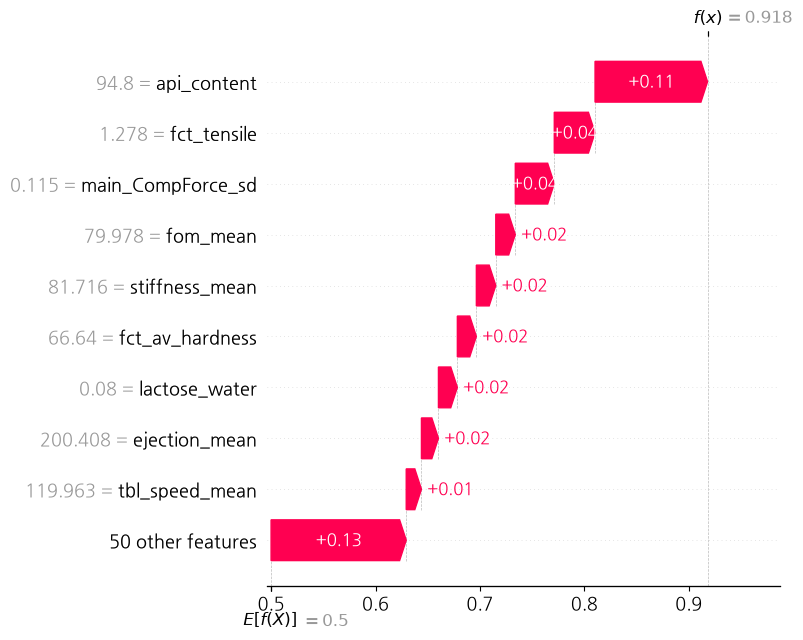

In [7]:
# 개별 배치 설명 — 경보가 뜬 배치의 근거를 보고서에 붙일 수 있다
alert_idx = np.where(p_te >= th_oper)[0]
i = int(alert_idx[np.argmax(p_te[alert_idx])]) if len(alert_idx) else 0
print(f"평가구간 {i}번째 배치 (원본 batch={df['batch'].iloc[te[i]]}): 위험 확률 {p_te[i]:.2f}, 실제 {'위험' if y[te[i]] else '적합'}")
shap.plots.waterfall(sv1[i], max_display=10, show=False)
plt.tight_layout(); plt.show()

## 5. 조기경보 시스템 설계 — 모델에서 운영으로
| 단계 | 설계 항목 | 예 |
|---|---|---|
| **입력** | 언제 예측하나 | 타정 종료 직후(시험 결과 나오기 전) |
| **출력** | 무엇을 주나 | 위험 확률 + 상위 기여 변수 3개 + 유사 과거 배치 |
| **등급** | 경보 수준 | 주의(0.3~0.6) / 경고(0.6 이상) |
| **조치** | 누가 무엇을 | 주의=QA 검토, 경고=추가 시험·일탈 절차 착수 |
| **기록** | 감사추적 | 모델 버전·입력값·출력·검토자·조치 결과 (예제 08) |
| **감시** | 성능 모니터링 | 월별 재현율·경보율·드리프트 (예제 08) |

> ⚠️ **AI 는 판정하지 않습니다.** GMP 에서 품질 판정의 책임은 **사람(QP·QA)** 에게 있으며,
> AI 출력은 **의사결정 지원 정보**입니다 (Human-in-the-loop).

In [8]:
# 운영 시뮬레이션: 평가 구간을 '실시간으로 들어오는 배치'처럼 처리
alerts = pd.DataFrame({
    "batch": df["batch"].iloc[te].values,
    "생산일": df["start_date"].iloc[te].dt.date.values,
    "위험확률": p_cal.round(3),
    "실제결과": np.where(y[te] == 1, "위험", "적합"),
})
alerts["등급"] = pd.cut(alerts["위험확률"], [-0.01, 0.3, 0.6, 1.01], labels=["정상", "주의", "경고"])
summary = alerts.groupby("등급", observed=True).agg(배치수=("batch", "size"), 실제위험=("실제결과", lambda s: (s == "위험").sum()))
summary["실제 위험 비율"] = (summary["실제위험"] / summary["배치수"]).round(3)
display(summary)
print("\n[경고] 등급 배치 목록 (상위 8건):")
display(alerts[alerts["등급"] == "경고"].sort_values("위험확률", ascending=False).head(8))

,배치수,실제위험,실제 위험 비율
등급,,,
정상,82,0,0.000
주의,106,37,0.349
경고,13,12,0.923



[경고] 등급 배치 목록 (상위 8건):


,batch,생산일,위험확률,실제결과,등급
3,813,2020-11-01,0.798,위험,경고
5,812,2020-11-01,0.798,위험,경고
154,938,2021-03-01,0.798,위험,경고
155,939,2021-03-01,0.798,위험,경고
156,940,2021-03-01,0.798,위험,경고
157,941,2021-03-01,0.798,위험,경고
158,942,2021-03-01,0.798,위험,경고
178,987,2021-04-01,0.798,위험,경고


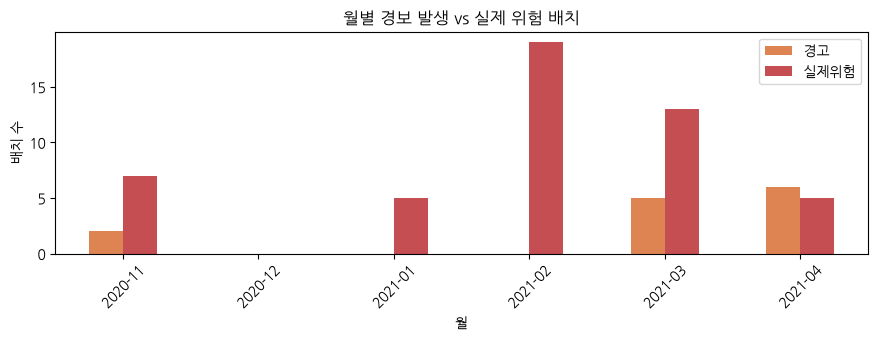

In [9]:
# 월별 경보 운영 현황 — 경보가 몰리는 시기가 있는지 확인
alerts["월"] = pd.to_datetime(alerts["생산일"]).dt.to_period("M").astype(str)
mon = alerts.groupby("월").agg(배치수=("batch", "size"), 경고=("등급", lambda s: (s == "경고").sum()),
                               실제위험=("실제결과", lambda s: (s == "위험").sum()))
ax = mon[["경고", "실제위험"]].plot.bar(figsize=(9, 3.5), color=["#DD8452", "#C44E52"])
ax.set_ylabel("배치 수"); ax.set_title("월별 경보 발생 vs 실제 위험 배치"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## 🧪 LLM 코딩 과제
```
X(특성), y(위험 배치 여부), tr/te(시간 순 분할 인덱스)가 있어.
C_FN(놓침 비용)을 5, 10, 20, 50으로 바꿔가며 비용 최소 임계값과 그때의 재현율·정밀도·경보발생률이
어떻게 변하는지 표로 만들고, 비용비율 대 임계값 그래프를 그려줘. 한글 주석을 달아줘.
```

In [10]:
# ✏️ LLM 코딩 과제 코드 붙여넣기

## ✅ 정리
| 개념 | 핵심 |
|---|---|
| 불균형 분류 | `class_weight` → **임계값 조정**이 가장 실용적 |
| 비용 기반 임계값 | FN·FP 비용비 **+ 경보율 상한**으로 결정. 검증 데이터로 정하고 평가 데이터로 확인 |
| 경보 운영 | 경보율 5~15%, 등급화, 경보 피로 관리 |
| 확률 보정 | 문서에 확률을 쓰려면 **보정 곡선·Brier** 확인 필수 |
| SHAP | 경보의 근거 제시 → 조사 시간 단축, 규제 설명 |
| 책임 | **AI 는 지원, 판정은 사람** (Human-in-the-loop) |

➡️ **다음 예제 06**: 정답 레이블이 없을 때 — **비지도 이상탐지와 일탈(Deviation) 자동 분류**